### Import Libraries

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from factor_analyzer import Rotator
from sklearn.metrics import silhouette_score
import geopandas as gpd
from sklearn_extra.cluster import CLARA
from sklearn.cluster import MiniBatchKMeans
from sqlalchemy import text, create_engine

### Import Data

In [2]:
# Step 1: Create the connection with the DB
engine = create_engine("postgresql://urbaninfo:@cirrus.ita.chalmers.se/emc2_15mc")
conn = engine.connect()

In [3]:
# Create a new schema when it is necessary
#conn.execute(text('''CREATE SCHEMA IF NOT EXISTS s7_paper_foreground_street_networks'''))
#conn.commit()

In [4]:
# Import data
# GOT_nms
got_nms_query = text('SELECT * FROM s8_paper_multiscalar_foreground_network."1_segment_nms_got_nonzeros_EPSG3857"')
got_nms = gpd.read_postgis(got_nms_query, engine, geom_col='geometry')

# VER_nms
ver_nms_query = text('''SELECT * FROM s8_paper_multiscalar_foreground_network."1_segment_nms_ver_nonzeros_EPSG3857"''')
ver_nms = gpd.read_postgis(ver_nms_query, engine, geom_col='geometry')

# NIC_nms
nic_nms_query = text('''SELECT * FROM s8_paper_multiscalar_foreground_network."1_segment_nms_nic_nonzeros_EPSG3857"''')
nic_nms = gpd.read_postgis(nic_nms_query, engine, geom_col='geometry')

# LIl_nms
lil_nms_query = text('''SELECT * FROM s8_paper_multiscalar_foreground_network."1_segment_nms_lil_nonzeros_EPSG3857"''')
lil_nms = gpd.read_postgis(lil_nms_query, engine, geom_col='geometry')

# VIE_nms
vie_nms_query = text('''SELECT * FROM s8_paper_multiscalar_foreground_network."1_segment_nms_vie_nonzeros_EPSG3857"''')
vie_nms = gpd.read_postgis(vie_nms_query, engine, geom_col='geometry')

### Pre-process the data

#### Correct the betweenness values by mean betweenness reached

In [5]:
def create_ratio_columns(df, radius_values=[500, 1000, 1500, 2000, 2500, 3000, 3500, 4000, 4500, 5000]):
    # Convert numeric values to match column names (e.g., 1000 → '1k')
    radius_labels = {1000: '1k', 2000: '2k', 3000: '3k', 4000: '4k', 5000: '5k' }
    formatted_radii = [radius_labels.get(r, r) for r in radius_values]

    # Loop through the formatted radius values
    for radius in formatted_radii:
        abw_col = f'abw{radius}'
        ar_col = f'arw{radius}ab'
        rw_col = f'rw{radius}l'

        # Ensure all required columns exist
        if {abw_col, ar_col, rw_col}.issubset(df.columns):
            new_col_name = f'norm_mbr_{radius}'
            df[new_col_name] = df[abw_col] / (df[ar_col]/ df[rw_col])

    return df


# Example usage
got_nms_norm_mbr = create_ratio_columns(got_nms).fillna(0)
nic_nms_norm_mbr = create_ratio_columns(nic_nms).fillna(0)
ver_nms_norm_mbr = create_ratio_columns(ver_nms).fillna(0)
lil_nms_norm_mbr = create_ratio_columns(lil_nms).fillna(0)
vie_nms_norm_mbr = create_ratio_columns(vie_nms).fillna(0)

#### Identify outliers

In [6]:
# Function to detect strict outliers in all 'norm_' columns
def detect_outliers_iqr(df, prefix='norm_', min_outlier_columns=1):
    norm_cols = [col for col in df.columns if col.startswith(prefix)]
    outlier_flags = pd.DataFrame(False, index=df.index, columns=norm_cols)

    for col in norm_cols:
        Q1 = df[col].quantile(0.05)
        Q3 = df[col].quantile(0.95)
        IQR = Q3 - Q1

        if IQR < 1e-6:
            continue

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outlier_flags[col] = (df[col] < lower_bound) | (df[col] > upper_bound)

    rows_with_enough_outliers = outlier_flags.sum(axis=1) >= min_outlier_columns
    return df[rows_with_enough_outliers]

# Dictionary of all city DataFrames
city_dfs = {
    'Gothenburg': got_nms_norm_mbr,
    'Versilia': ver_nms_norm_mbr,
    'Nice': nic_nms_norm_mbr,
    'Lille': lil_nms_norm_mbr,
    'Vienna': vie_nms_norm_mbr
}

# Loop through cities, detect and print strict outliers
for city_name, city_df in city_dfs.items():
    outliers = detect_outliers_iqr(city_df, min_outlier_columns=10)

    print(f"\n--- {city_name} ---")
    if outliers.empty:
        print("No rows are outliers in all 10 'norm_' columns.")
    else:
        print(f"{len(outliers)} outliers detected in all 10 'norm_' columns.")
        print(outliers)


--- Gothenburg ---
No rows are outliers in all 10 'norm_' columns.

--- Versilia ---
2 outliers detected in all 10 'norm_' columns.
         fid                                           geometry     id  \
11086  11087  LINESTRING (1129889.938 5463617.742, 1129956.2...  11087   
55079  55080  LINESTRING (1129956.229 5463673.659, 1129959.1...  55080   

                          uv  abw500    abw1k   abw1500     abw2k   abw2500  \
11086  1778930680_1777980958  8798.5  71572.0  232426.5  522523.0  941424.0   
55079  1777980958_1769208440  8926.5  71773.5  232993.5  523258.0  942742.0   

             abw3k  ...  norm_mbr_500  norm_mbr_1k  norm_mbr_1500  \
11086  1578354.125  ...    125.723512   156.823122     189.611511   
55079  1580463.625  ...    120.215379   158.076022     188.677945   

       norm_mbr_2k  norm_mbr_2500  norm_mbr_3k  norm_mbr_3500  norm_mbr_4k  \
11086   187.309695     179.422275   207.328440     241.888825   259.219338   
55079   183.389875     176.982048   206.70

In [7]:
# List of FID values to remove
fids_to_remove_nic = [8464, 8465, 8681, 264661, 264662, 451827, 453255, 453256]
fids_to_remove_ver = [11087 , 55080]

# Drop rows where 'fid' is in that list
nic_nms_norm_mbr = nic_nms_norm_mbr[~nic_nms_norm_mbr['fid'].isin(fids_to_remove_nic)]
ver_nms_norm_mbr = ver_nms_norm_mbr[~ver_nms_norm_mbr['fid'].isin(fids_to_remove_ver)]

## PCA analysis

#### Create the PCs, and test the variance

In [8]:
# Create a dictionary to concatenate the tables of the different cities
cities = {'Gothenburg': got_nms_norm_mbr, 'Versilia': ver_nms_norm_mbr,
          'Nice':nic_nms_norm_mbr, 'Lille':lil_nms_norm_mbr,
          'Vienna':vie_nms_norm_mbr}
# Display to check
print(cities)

{'Gothenburg':            fid                                           geometry      id  \
0            1  LINESTRING (1342159.842 7883580.812, 1342181.1...       1   
1            2  LINESTRING (1342169.171 7883499.833, 1342181.1...       2   
2            3  LINESTRING (1345950.739 7898301.149, 1345956.5...       3   
3            4  LINESTRING (1345947.221 7898257.083, 1345950.7...       4   
4            5  LINESTRING (1345954.679 7898196.095, 1345949.8...       5   
...        ...                                                ...     ...   
405277  406436  LINESTRING (1329698.249 7877830.647, 1329699.4...  406436   
405278  406437  LINESTRING (1329695.555 7877821.451, 1329698.2...  406437   
405279  406438  LINESTRING (1329692.95 7877815.12, 1329695.555...  406438   
405280  406439  LINESTRING (1329689.588 7877808.912, 1329692.9...  406439   
405281  406440  LINESTRING (1329687.127 7877795.773, 1329689.5...  406440   

                           uv   abw500     abw1k   abw1500  

In [9]:
city_pca_results = {}
explained_variance = {}
pca_loadings = {}
n_components = 3  # Adjust as needed

# Set the seed number
seed_number = 3011

# Loop through each city's DataFrame to standardize and perform PCA
for city_name, data in cities.items():
    filtered_cols = [col for col in data.columns if col.startswith('norm_mbr')]
    city_data = data[filtered_cols]

    # Standardize data and perform PCA
    pca = PCA(n_components=n_components, random_state=seed_number)
    transformed_data = pca.fit_transform(StandardScaler().fit_transform(city_data))

    # Store explained variance and loadings
    explained_variance[city_name] = pca.explained_variance_ratio_
    pca_loadings[city_name] = pca.components_.T  # Store loadings (transpose for feature alignment)

    # Create a DataFrame for PCA results and store it
    city_pca_results[city_name] = pd.concat([data.reset_index(drop=True),
                                             pd.DataFrame(transformed_data,
                                                          columns=[f'PC{i + 1}' for i in range(n_components)])], axis=1)

# Create DataFrame
pca_results_combined = pd.concat(city_pca_results.values(), keys=city_pca_results.keys(), names=['city']).reset_index(level=0)

#### Plot the variance

Explained Variance Ratios by City:
Gothenburg: [0.8009248  0.13477472 0.04239913]
Versilia: [0.79893787 0.1319059  0.04501573]
Nice: [0.78992965 0.13464324 0.04900428]
Lille: [0.764967   0.14089716 0.06054187]
Vienna: [0.79732385 0.13282433 0.04673725]

Total Explained Variance by City:
Gothenburg: 0.9781
Versilia: 0.9759
Nice: 0.9736
Lille: 0.9664
Vienna: 0.9769


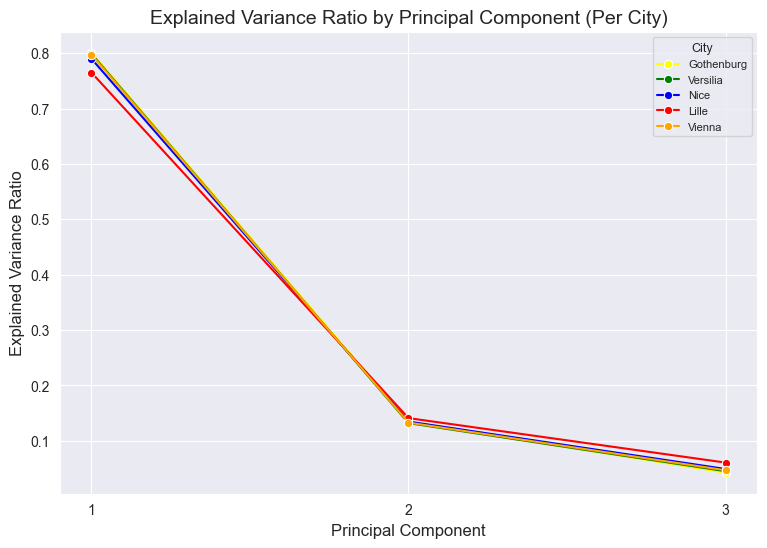

In [10]:
# Print explained variance ratios
print("Explained Variance Ratios by City:")
for city, variance in explained_variance.items():
    print(f"{city}: {variance}")

print("\nTotal Explained Variance by City:")
for city, total_variance in {city: sum(var) for city, var in explained_variance.items()}.items():
    print(f"{city}: {total_variance:.4f}")

plt.figure(figsize=(9, 6))

hue_color_map = {'Versilia': 'green', 'Gothenburg': 'yellow', 'Nice':'blue', 'Lille': 'red', 'Vienna':'orange'}

# Loop through each city to plot its explained variance
for city, variance in explained_variance.items():
    sns.lineplot(x=range(1, n_components + 1), y=variance, color=hue_color_map[city], marker='o', label=city)

# Add titles and labels
plt.title('Explained Variance Ratio by Principal Component (Per City)', fontsize=14)
plt.xlabel('Principal Component', fontsize=12)
plt.ylabel('Explained Variance Ratio', fontsize=12)
plt.xticks(ticks=range(1, n_components + 1))
plt.legend(title="City", fontsize=8, title_fontsize=9)
plt.savefig('C:/Users/monaliza/PycharmProjects/paper-multiscalar-foreground-network/0_data-visualization/1-mbr-variance-ratio.png', format='png', dpi=300, bbox_inches='tight')
plt.show()

#### Create the rotated components

In [11]:
pca_rotated = {}

# Apply varimax rotation to PCA loadings per city
for city_name, loadings in pca_loadings.items():
    rotator = Rotator(method='varimax', normalize=True)
    rotated_loadings = rotator.fit_transform(loadings)

    # Identify ABw columns from the corresponding city's DataFrame
    norm_columns = [col for col in cities[city_name].columns if col.startswith('norm_')]

    # Store rotated loadings as DataFrame
    pca_rotated[city_name] = pd.DataFrame(
        rotated_loadings,
        columns=[f'RC{i + 1}' for i in range(rotated_loadings.shape[1])],
        index=norm_columns
    )

# Combine all cities' rotated components into a single DataFrame
pca_rotated_components = (
    pd.concat(pca_rotated.values(), keys=pca_rotated.keys())
    .reset_index()
    .rename(columns={'level_0': 'city', 'level_1': 'Radius'})
)

#### Plot the rotated components

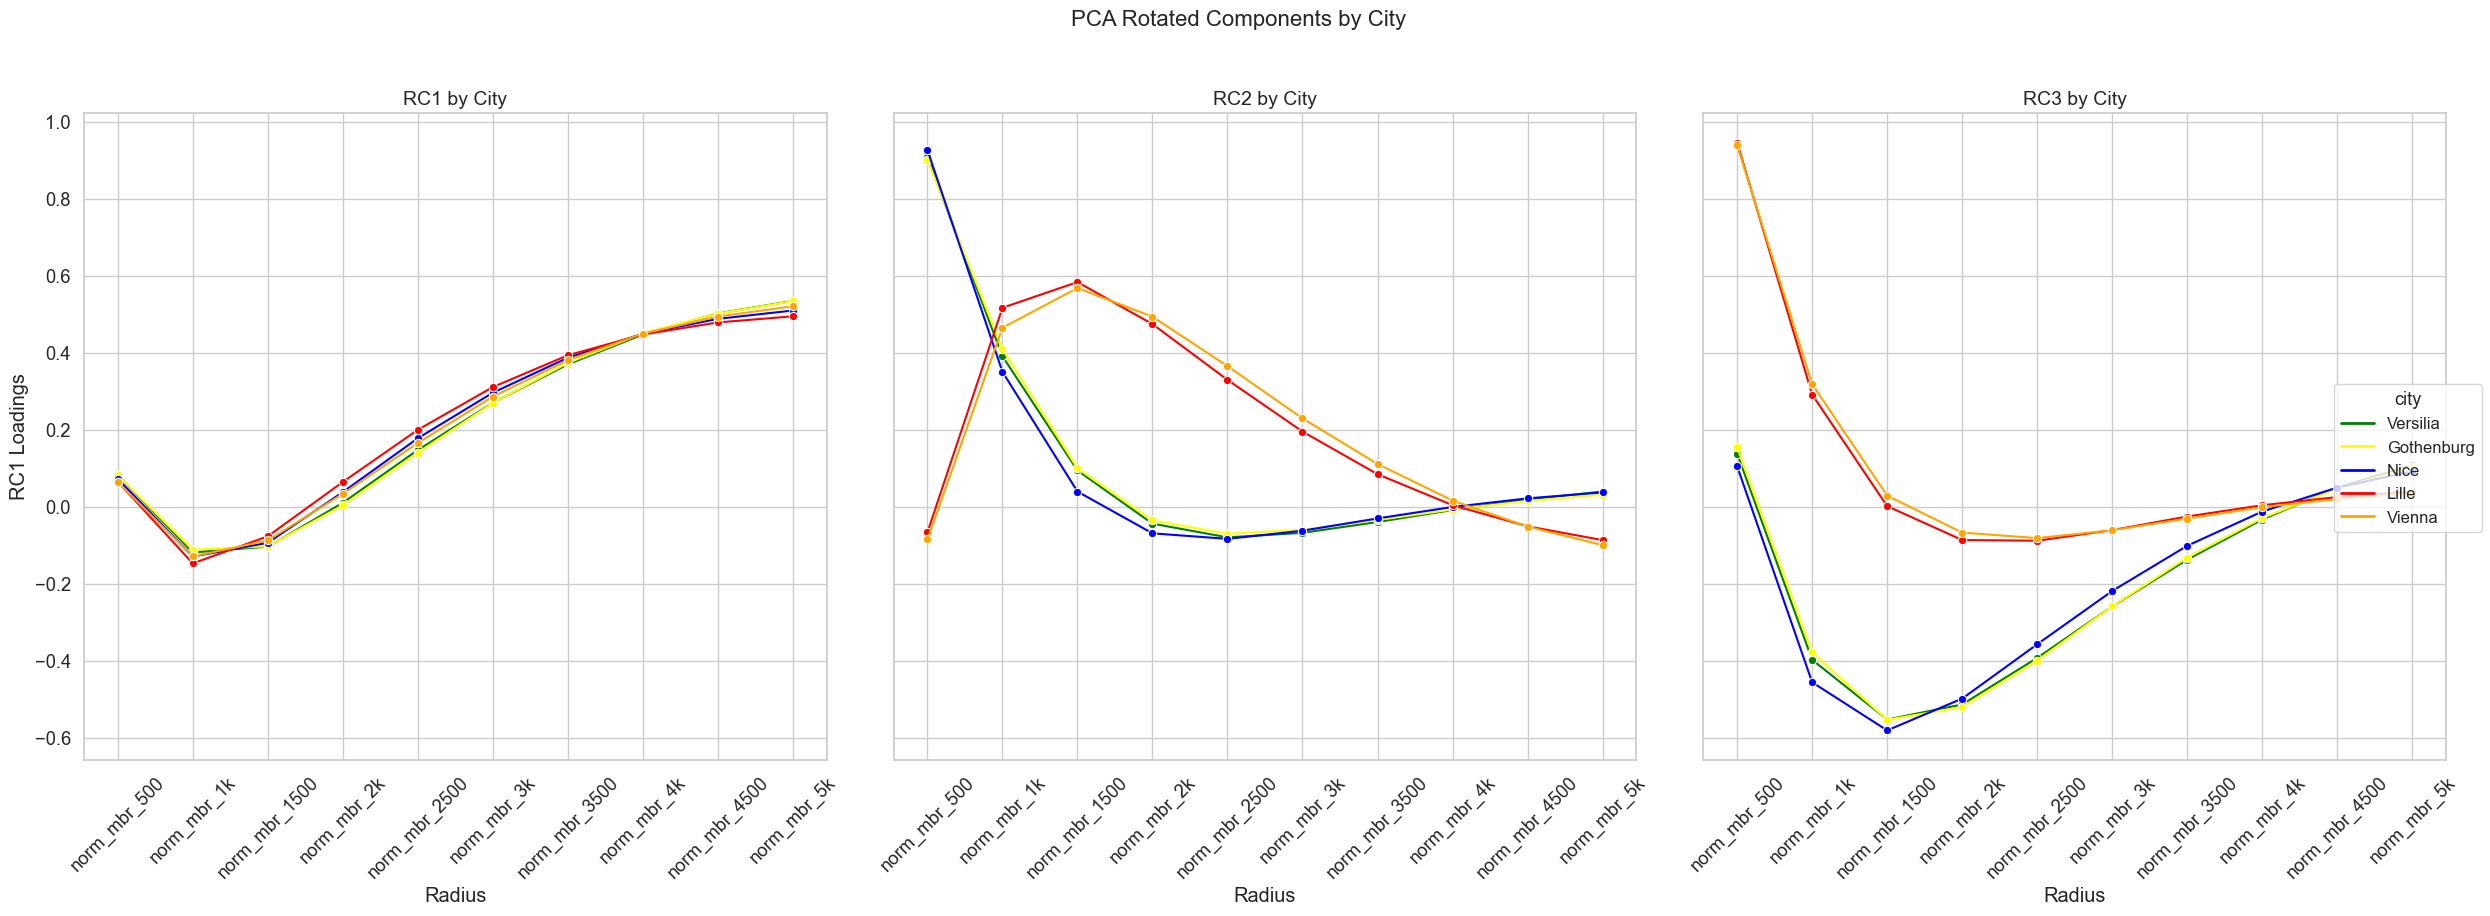

In [12]:
# Set seaborn plot style and aesthetics
sns.set(style='whitegrid', palette='muted', font_scale=1.2)
fig, axes = plt.subplots(1, 3, figsize=(25, 9), sharey=True)

# Define custom color mapping for each city
hue_color_map = {'Versilia': 'green', 'Gothenburg': 'yellow', 'Nice': 'blue', 'Lille': 'red', 'Vienna': 'orange'}

# Function to plot a single rotated PCA component for all cities
def plot_pca_component(component, ax, title):
    for city, color in hue_color_map.items():
        # Filter data for the current city
        city_data = pca_rotated_components[pca_rotated_components['city'] == city]
        # Plot line with markers for the current city and component
        sns.lineplot(data=city_data, x='Radius', y=component, color=color, ax=ax, marker='o', label=city, legend=False)

    # Set plot title and labels
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Radius')
    ax.set_ylabel(f'{component} Loadings')
    ax.tick_params(axis='x', rotation=45)

# Plot the first three rotated PCA components (RC1, RC2, RC3)
plot_pca_component('RC1', axes[0], 'RC1 by City')
plot_pca_component('RC2', axes[1], 'RC2 by City')
plot_pca_component('RC3', axes[2], 'RC3 by City')

# Add titles and labels, export the image
plt.suptitle('PCA Rotated Components by City', fontsize=16, y=1.02)
plt.figlegend( handles=[plt.Line2D([0], [0], color=color, lw=2) for color in hue_color_map.values()], labels=hue_color_map.keys(),
               loc='right', fontsize=12, title='city',title_fontsize='13')
plt.savefig('C:/Users/monaliza/PycharmProjects/paper-multiscalar-foreground-network/0_data-visualization/2-mbr-rotated-components.png', format='png',dpi=300,bbox_inches='tight')
plt.tight_layout()
plt.show()

#### Invert and swap components (when it is necessary)

In [13]:
# Create a copy of the original DataFrame
pca_rotated_components_adjusted = pca_rotated_components.copy()

# Swap RC2 and RC3 for Vienna
mask_vienna = pca_rotated_components_adjusted['city'] == 'Vienna'
temp_rc2_vienna = pca_rotated_components_adjusted.loc[mask_vienna, 'RC2'].copy()
pca_rotated_components_adjusted.loc[mask_vienna, 'RC2'] = pca_rotated_components_adjusted.loc[mask_vienna, 'RC3']
pca_rotated_components_adjusted.loc[mask_vienna, 'RC3'] = temp_rc2_vienna

# Swap RC2 and RC3 for Lille
mask_lille = pca_rotated_components_adjusted['city'] == 'Lille'
temp_rc2_lille = pca_rotated_components_adjusted.loc[mask_lille, 'RC2'].copy()
pca_rotated_components_adjusted.loc[mask_lille, 'RC2'] = pca_rotated_components_adjusted.loc[mask_lille, 'RC3']
pca_rotated_components_adjusted.loc[mask_lille, 'RC3'] = temp_rc2_lille

In [14]:
# Function to invert selected RCs for a given city
def adjust_rc_columns(df, city_name, *rc_columns):
    for col in rc_columns:
        df[col] = np.where(df['city'] == city_name, df[col] * -1, df[col])
    return df

# Invert RC3 for both cities
pca_rotated_components_adjusted = adjust_rc_columns(pca_rotated_components_adjusted, 'Vienna', 'RC3')
pca_rotated_components_adjusted = adjust_rc_columns(pca_rotated_components_adjusted, 'Lille', 'RC3')

#### Plot the rotated components

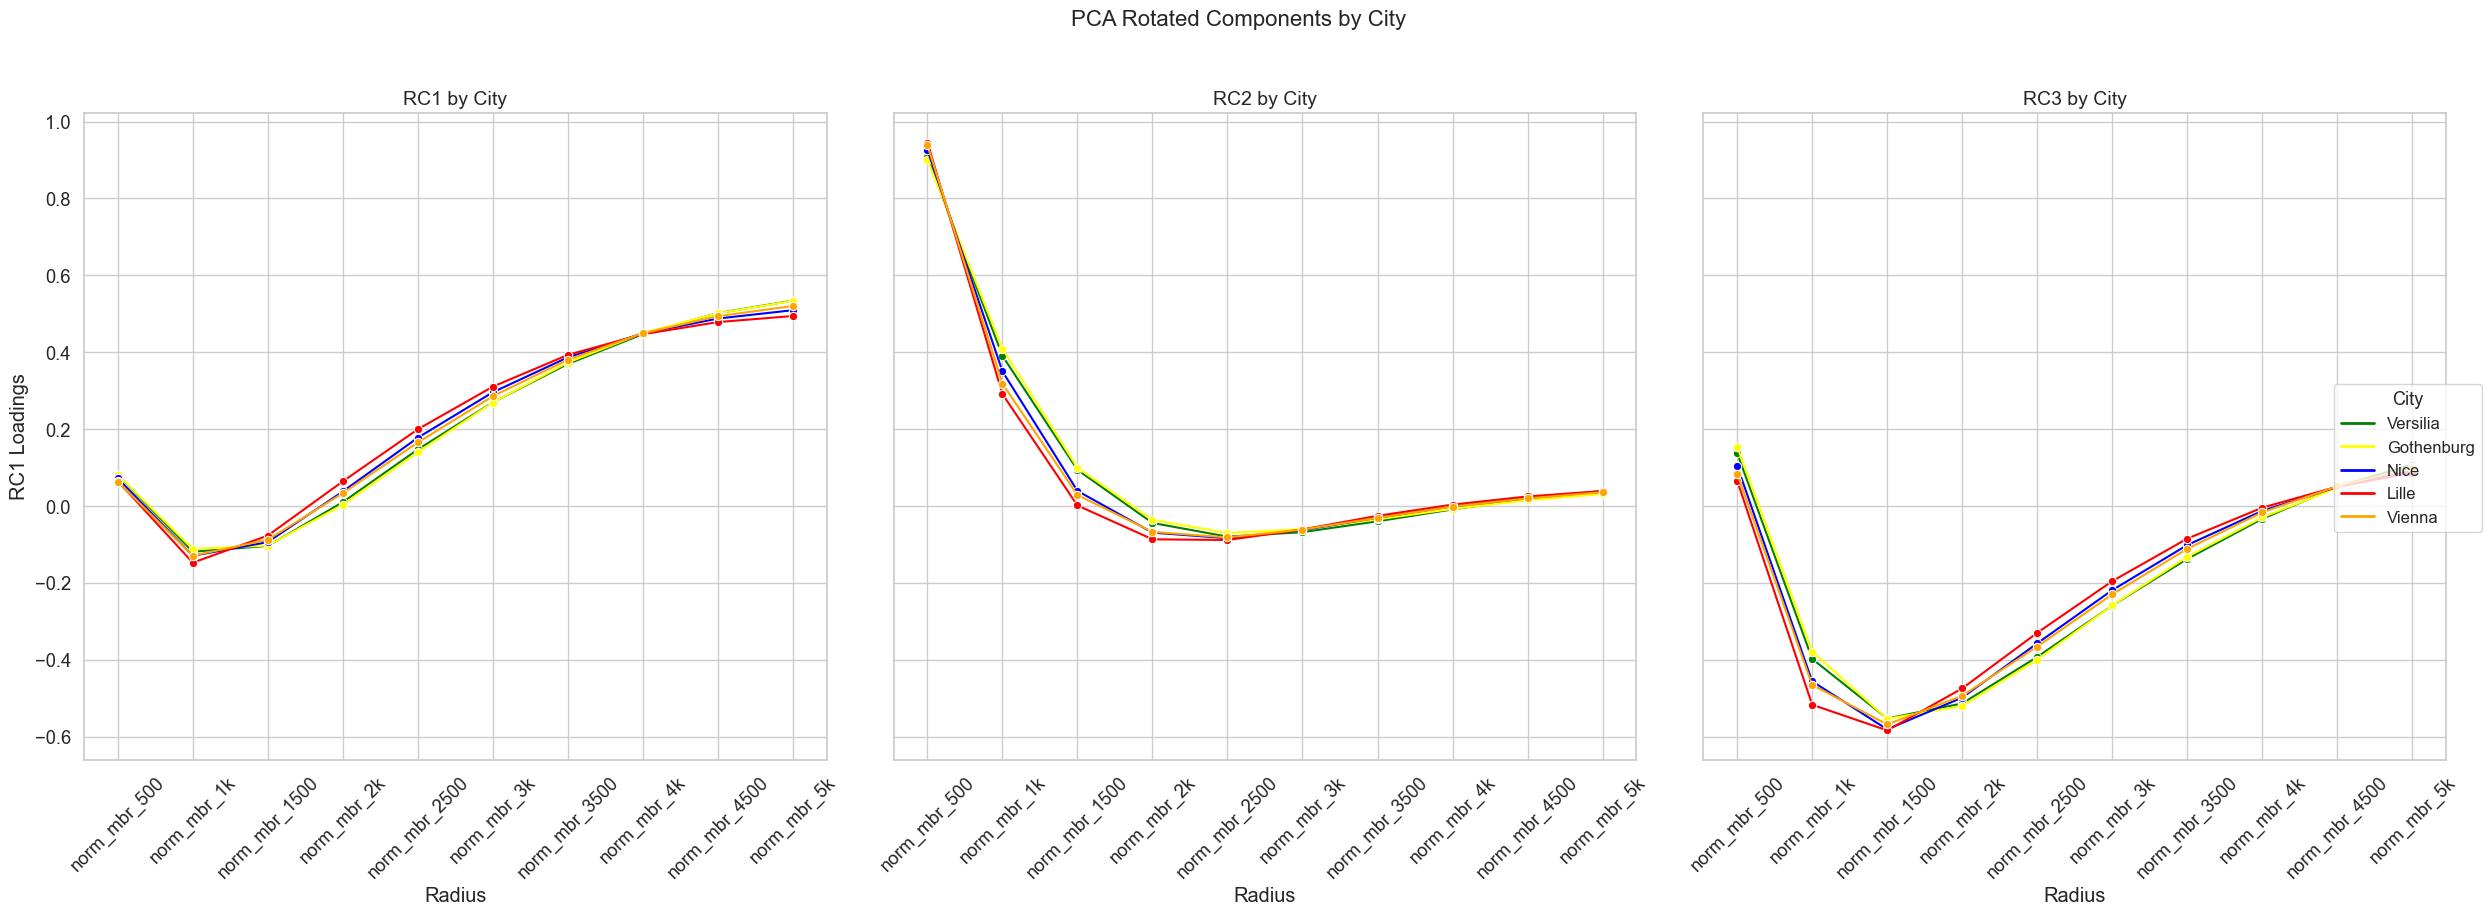

In [15]:
# Plot PCA Rotated Components
sns.set(style='whitegrid', palette='muted', font_scale=1.2)
fig, axes = plt.subplots(1, 3, figsize=(25, 9), sharey=True)

hue_color_map = {'Versilia': 'green', 'Gothenburg': 'yellow', 'Nice':'blue', 'Lille': 'red', 'Vienna':'orange'}


def plot_pca_component(component, ax, title):
    for city, color in hue_color_map.items():
        city_data = pca_rotated_components_adjusted[pca_rotated_components_adjusted['city'] == city]
        sns.lineplot(data=city_data, x='Radius', y=component, color=color, ax=ax, marker='o', label=city, legend=False)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Radius')
    ax.set_ylabel(f'{component} Loadings')
    ax.tick_params(axis='x', rotation=45)


plot_pca_component('RC1', axes[0], 'RC1 by City')
plot_pca_component('RC2', axes[1], 'RC2 by City')
plot_pca_component('RC3', axes[2], 'RC3 by City')

plt.suptitle('PCA Rotated Components by City', fontsize=16, y=1.02)
plt.tight_layout()
plt.figlegend(handles=[plt.Line2D([0], [0], color=color, lw=2) for color in hue_color_map.values()],
              labels=hue_color_map.keys(), loc='right', fontsize=12, title='City', title_fontsize='13')
plt.savefig('C:/Users/monaliza/PycharmProjects/paper-multiscalar-foreground-network/0_data-visualization/2-mbr-rotated-components-adjusted.png', format='png', dpi=300, bbox_inches='tight')
plt.show()

#### Filter and Export the results combined and per city

In [16]:
# Function filter:
def filter_gdf(gdf, city_name):
    gdf_filtered = gdf[gdf['city'] == city_name]
    return gdf_filtered

got_pca_results = filter_gdf(pca_results_combined, 'Gothenburg')
ver_pca_results = filter_gdf(pca_results_combined, 'Versilia')
nic_pca_results = filter_gdf(pca_results_combined, 'Nice')
lil_pca_results = filter_gdf(pca_results_combined, 'Lille')
vie_pca_results = filter_gdf(pca_results_combined, 'Vienna')

In [17]:
# Function export:
def export(gdf, table_name, schema_name, engine):
    gdf.to_postgis(
        table_name,
        engine,
        schema=schema_name,
        if_exists='replace'
    )
# Export
export(pca_results_combined, '3_mbr_pca_results_nms_combined_cities_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(got_pca_results, '3_mbr_pca_results_nms_got_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(ver_pca_results, '3_mbr_pca_results_nms_ver_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(nic_pca_results, '3_mbr_pca_results_nms_nic_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(lil_pca_results, '3_mbr_pca_results_nms_lil_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(vie_pca_results, '3_mbr_pca_results_nms_lil_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)

## Clustering

#### Check the Silhouette Score

For n_clusters = 3, the average silhouette_score is : 0.5007
For n_clusters = 4, the average silhouette_score is : 0.4917
For n_clusters = 5, the average silhouette_score is : 0.3956
For n_clusters = 6, the average silhouette_score is : 0.3954
For n_clusters = 7, the average silhouette_score is : 0.3347
For n_clusters = 8, the average silhouette_score is : 0.3219
For n_clusters = 9, the average silhouette_score is : 0.3033


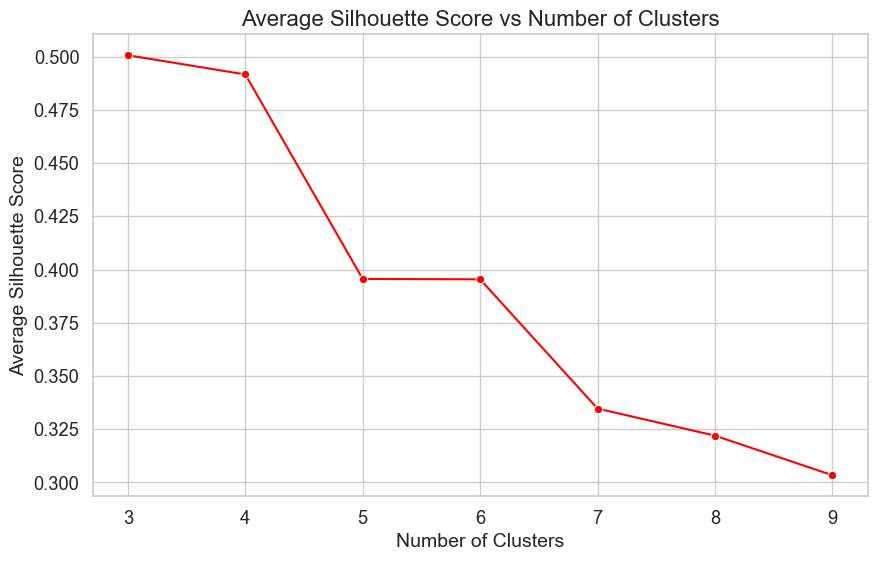

In [18]:
# Define variables
range_n_clusters = list(range(3,10))
sample_pca_results = pca_results_combined[['PC1', 'PC2', 'PC3']].sample(25000, random_state=seed_number)

# Standardize the sample data
scaler = StandardScaler()
sample_pca_results = scaler.fit_transform(sample_pca_results)

# Initialize list to store silhouette scores
silhouette_scores = []
cluster_labels_list = []

# Loop through each number of clusters
for n_clusters in range_n_clusters:
    clusterer = MiniBatchKMeans(n_clusters=n_clusters, random_state=seed_number, batch_size=3072)
    cluster_labels = clusterer.fit_predict(sample_pca_results)

    silhouette_avg = silhouette_score(sample_pca_results, cluster_labels)
    silhouette_scores.append(silhouette_avg)  # Store the average silhouette score
    cluster_labels_list.append(cluster_labels)  # Store cluster labels for each n_clusters
    print(f"For n_clusters = {n_clusters}, the average silhouette_score is : {silhouette_avg:.4f}")

# Create a line plot for silhouette scores
plt.figure(figsize=(10, 6))
sns.lineplot(x=range_n_clusters, y=silhouette_scores, marker='o', color='red')
plt.title('Average Silhouette Score vs Number of Clusters', fontsize=16)
plt.xlabel('Number of Clusters', fontsize=14)
plt.ylabel('Average Silhouette Score', fontsize=14)
plt.xticks(range_n_clusters)  # Set x-ticks to the number of clusters
plt.grid(True)
plt.savefig('C:/Users/monaliza/PycharmProjects/paper-multiscalar-foreground-network/0_data-visualization/3-mbr-elbow.png', format='png', dpi=300, bbox_inches='tight')
plt.show()

#### Clusterize using Clara method (K-medoids)

In [19]:
# Do we need to scale the pca here as well?
# Create a copy of the original DataFrame
combined_pca_clustering_results = pca_results_combined.copy()

# Extract relevant columns (adjust column indices as needed)
combined_pca_clustering_results_filtered = combined_pca_clustering_results [['PC1', 'PC2', 'PC3']]  # Selecting columns 12 to 5

# # Testing Scaling: Standardize the sample data
scaler = StandardScaler()
combined_pca_clustering_results_filtered = scaler.fit_transform(combined_pca_clustering_results_filtered)

# Initialize the CLARA model
clara_model = CLARA(n_clusters=4, metric='euclidean', n_sampling=10000, random_state=seed_number)

# Fit the model to your data
clara_model.fit(combined_pca_clustering_results_filtered)

# Get the labels assigned to each point
labels = clara_model.labels_

# Get the cluster centers (medoids)
medoids = clara_model.cluster_centers_

# Add the cluster labels to the original DataFrame (optional)
combined_pca_clustering_results['cluster_4'] = labels

# Plot the table
combined_pca_clustering_results.head()

,city,fid,geometry,id,uv,abw500,abw1k,abw1500,abw2k,abw2500,...,norm_mbr_2500,norm_mbr_3k,norm_mbr_3500,norm_mbr_4k,norm_mbr_4500,norm_mbr_5k,PC1,PC2,PC3,cluster_4
0,Gothenburg,1.0,"LINESTRING (1342159.842 7883580.812, 1342181.1...",1,148923_2613675388,3030.0,32290.5,72624.50,150848.50,245350.50,...,12.159436,12.904782,12.691311,11.876547,10.693267,9.446758,-0.360178,-0.435819,-0.291701,2
1,Gothenburg,2.0,"LINESTRING (1342169.171 7883499.833, 1342181.1...",2,148923_2613675332,2869.0,31370.5,70602.50,146965.00,239544.00,...,11.721376,12.558761,12.348099,11.593132,10.436182,9.214429,-0.409213,-0.451086,-0.285408,2
2,Gothenburg,3.0,"LINESTRING (1345950.739 7898301.149, 1345956.5...",3,162381_5706052174,1876.5,28714.5,93314.75,222719.50,428228.00,...,23.551090,23.801916,27.171503,32.222812,36.236985,37.031848,2.239376,-0.232976,-0.753413,1
3,Gothenburg,4.0,"LINESTRING (1345947.221 7898257.083, 1345950.7...",4,162381_270591673,1969.0,28880.0,94004.75,224205.00,431086.00,...,23.241443,23.864816,27.240952,32.427808,36.369763,37.056078,2.210864,-0.227270,-0.660021,1
4,Gothenburg,5.0,"LINESTRING (1345954.679 7898196.095, 1345949.8...",5,162382_360626365,2077.0,8184.5,17485.00,26618.75,37945.25,...,1.942819,1.561242,1.431518,1.328753,1.338794,1.240121,-1.377815,0.071197,0.124693,0


#### Filter

In [20]:
# Function "filter gdf":
got_clustering_results = filter_gdf(combined_pca_clustering_results, 'Gothenburg')
ver_clustering_results = filter_gdf(combined_pca_clustering_results, 'Versilia')
nic_clustering_results = filter_gdf(combined_pca_clustering_results, 'Nice')
lil_clustering_results = filter_gdf(combined_pca_clustering_results, 'Lille')
vie_clustering_results = filter_gdf(combined_pca_clustering_results, 'Vienna')

#### Reproject

In [21]:
# Function reproject the gdf:
def reproject_crs(gdf, crs):
    gdf_reprojected = gdf.to_crs(crs)

    return gdf_reprojected
# Reproject
got_clustering_results_original_projection = reproject_crs(got_clustering_results, 'EPSG:3006')
ver_clustering_results_original_projection = reproject_crs(ver_clustering_results, 'EPSG:3003')
nic_clustering_results_original_projection = reproject_crs(nic_clustering_results, 'EPSG:2154')
lil_clustering_results_original_projection = reproject_crs(lil_clustering_results, 'EPSG:2154')
vie_clustering_results_original_projection = reproject_crs(vie_clustering_results, 'EPSG:31256')

#### Export

In [22]:
# Function "export":
export(combined_pca_clustering_results, '3_mbr_cluster_results_nms_combined_cities_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(got_clustering_results_original_projection, '3_mbr_cluster_results_nms_got_EPSG3006', 's8_paper_multiscalar_foreground_network', engine)
export(ver_clustering_results_original_projection, '3_mbr_cluster_results_nms_ver_EPSG3003', 's8_paper_multiscalar_foreground_network', engine)
export(nic_clustering_results_original_projection , '3_mbr_cluster_results_nms_nic_EPSG2154', 's8_paper_multiscalar_foreground_network', engine)
export(lil_clustering_results_original_projection , '3_mbr_cluster_results_nms_lil_EPSG2154', 's8_paper_multiscalar_foreground_network', engine)
export(vie_clustering_results_original_projection , '3_mbr_cluster_results_nms_vie_EPSG2154', 's8_paper_multiscalar_foreground_network', engine)

### Data Visualisation

#### Visualise: group the number by zscores, plot the data

In [23]:
# Copy the original DataFrame
combined_pca_clustering_zscore_results = combined_pca_clustering_results.copy()

# Define the prefixes for z-score scaling
prefixes = ['norm_', 'abw']

# Initialize the scaler
scaler = StandardScaler()

# Iterate through each prefix to scale and add z-score columns
for prefix in prefixes:
    # Filter columns starting with the current prefix
    selected_columns = [col for col in combined_pca_clustering_results.columns if col.startswith(prefix)]

    # Fit and transform the selected columns
    zscore_values = scaler.fit_transform(combined_pca_clustering_results[selected_columns])

    # Create a DataFrame with the scaled values
    zscore_df = pd.DataFrame(zscore_values, columns=[f'zscore_{col}' for col in selected_columns], index=combined_pca_clustering_results.index)

    # Add the z-score columns back to the original DataFrame
    combined_pca_clustering_results = pd.concat([combined_pca_clustering_results, zscore_df], axis=1)

# Display the updated DataFrame with z-scores
combined_pca_clustering_results.head()

,city,fid,geometry,id,uv,abw500,abw1k,abw1500,abw2k,abw2500,...,zscore_abw500,zscore_abw1k,zscore_abw1500,zscore_abw2k,zscore_abw2500,zscore_abw3k,zscore_abw3500,zscore_abw4k,zscore_abw4500,zscore_abw5k
0,Gothenburg,1.0,"LINESTRING (1342159.842 7883580.812, 1342181.1...",1,148923_2613675388,3030.0,32290.5,72624.50,150848.50,245350.50,...,0.308419,0.779176,0.444993,0.377964,0.280480,0.175714,0.096663,0.035762,-0.014826,-0.050966
1,Gothenburg,2.0,"LINESTRING (1342169.171 7883499.833, 1342181.1...",2,148923_2613675332,2869.0,31370.5,70602.50,146965.00,239544.00,...,0.267153,0.744881,0.421724,0.358861,0.265767,0.164253,0.087450,0.028487,-0.020719,-0.055818
2,Gothenburg,3.0,"LINESTRING (1345950.739 7898301.149, 1345956.5...",3,162381_5706052174,1876.5,28714.5,93314.75,222719.50,428228.00,...,0.012768,0.645874,0.683098,0.731501,0.743865,0.808545,0.850456,0.865886,0.796053,0.697549
3,Gothenburg,4.0,"LINESTRING (1345947.221 7898257.083, 1345950.7...",4,162381_270591673,1969.0,28880.0,94004.75,224205.00,431086.00,...,0.036477,0.652043,0.691039,0.738809,0.751107,0.815066,0.856170,0.870810,0.800533,0.701432
4,Gothenburg,5.0,"LINESTRING (1345954.679 7898196.095, 1345949.8...",5,162382_360626365,2077.0,8184.5,17485.00,26618.75,37945.25,...,0.064158,-0.119419,-0.189557,-0.233129,-0.245054,-0.248052,-0.246818,-0.246821,-0.243259,-0.239970


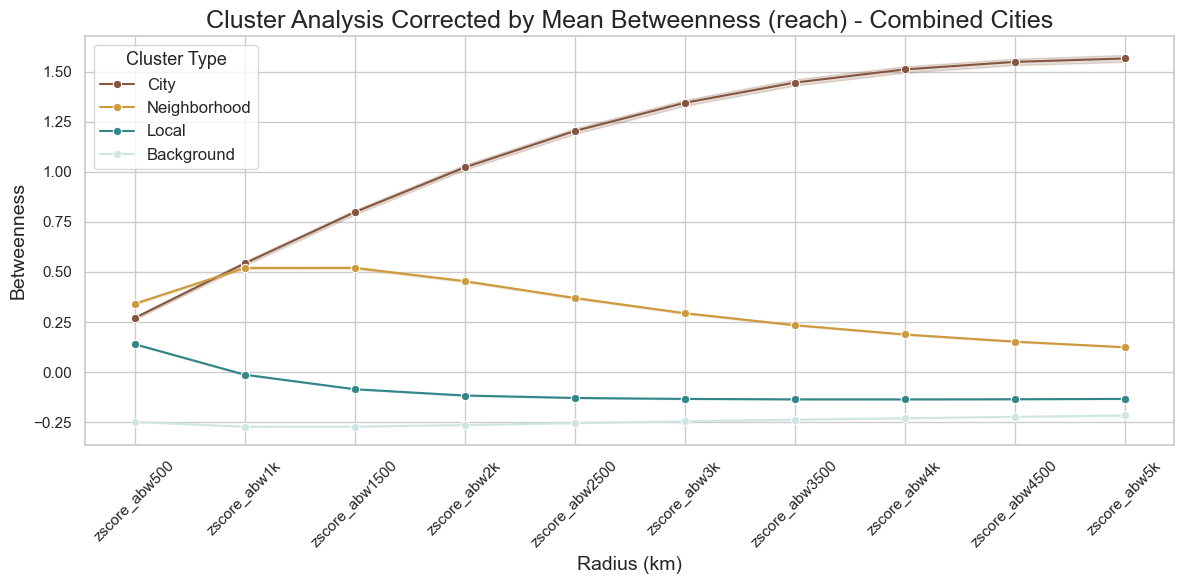

In [28]:
# Define corrected colors for each cluster type
cluster_palette = {
    'City': '#85563F',         # marrom
    'Neighborhood': '#cd993f', # mostarda
    'Local': '#338687',        # teal
    'Background': '#cfe5e3'    # azul claro
}

# Map numeric cluster labels (0–3) to corrected descriptive names
cluster_label_map = {
    0: 'Local',
    1: 'Neighborhood',
    2: 'Background',
    3: 'City'
}

# Order for plotting and legend (matches desired label-color association)
cluster_order = ['City', 'Neighborhood', 'Local', 'Background']

# Filter the columns that start with 'zscore_abw'
zscore_columns = [col for col in combined_pca_clustering_results.columns if col.startswith('zscore_abw')]

# Map numeric cluster values to descriptive labels
combined_pca_clustering_results['cluster_4_label'] = combined_pca_clustering_results['cluster_4'].map(cluster_label_map)

# Melt the DataFrame for seaborn plotting
melted_zscore = combined_pca_clustering_results.melt(
    id_vars=['cluster_4_label'],
    value_vars=zscore_columns,
    var_name='zscore variable',
    value_name='value'
)

# Set seaborn style
sns.set(style='whitegrid')

# Plot
plt.figure(figsize=(12, 6))
ax = sns.lineplot(
    data=melted_zscore,
    x='zscore variable',
    y='value',
    hue='cluster_4_label',
    hue_order=cluster_order,
    marker='o',
    palette=cluster_palette
)

# Customize the plot
plt.title('Cluster Analysis Corrected by Mean Betweenness (reach) - Combined Cities', fontsize=18)
plt.xlabel('Radius (km)', fontsize=14)
plt.ylabel('Betweenness', fontsize=14)
plt.xticks(rotation=45)

# Reorder legend manually
handles, labels = ax.get_legend_handles_labels()
label_to_handle = dict(zip(labels, handles))
ordered_handles = [label_to_handle[label] for label in cluster_order if label in label_to_handle]

plt.legend(
    handles=ordered_handles,
    labels=cluster_order,
    title='Cluster Type',
    fontsize=12,
    title_fontsize=13,
    loc='upper left'
)

plt.grid(True)
plt.tight_layout()

# Save and show the plot
plt.savefig(
    'C:/Users/monaliza/PycharmProjects/paper-multiscalar-foreground-network/0_data-visualization/4-mbr-cluster-lineplot-combined.png',
    format='png', dpi=300, bbox_inches='tight'
)
plt.show()

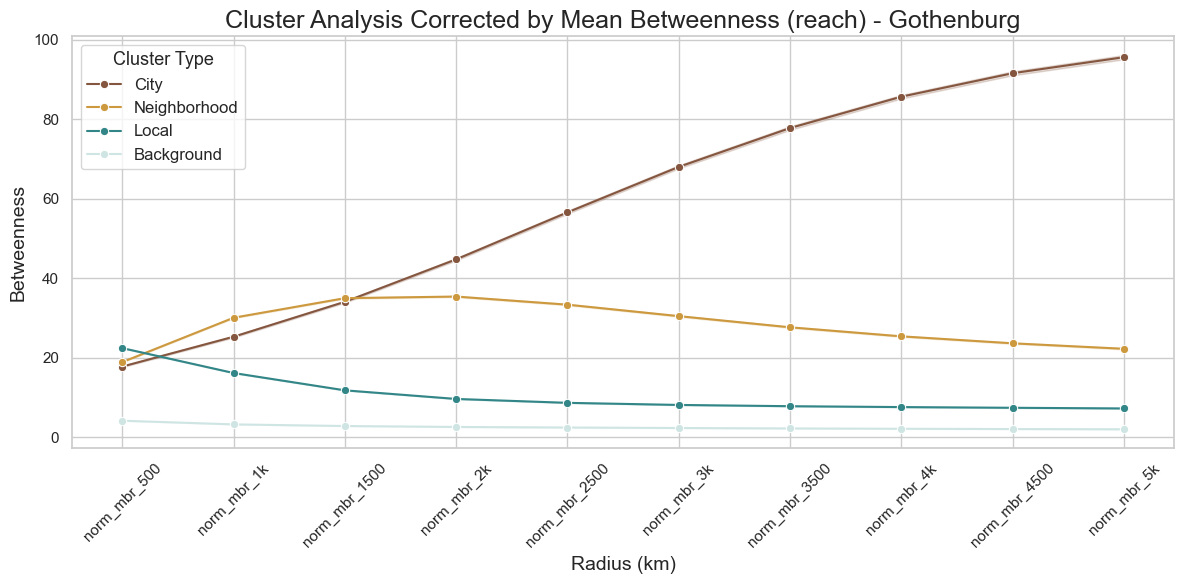

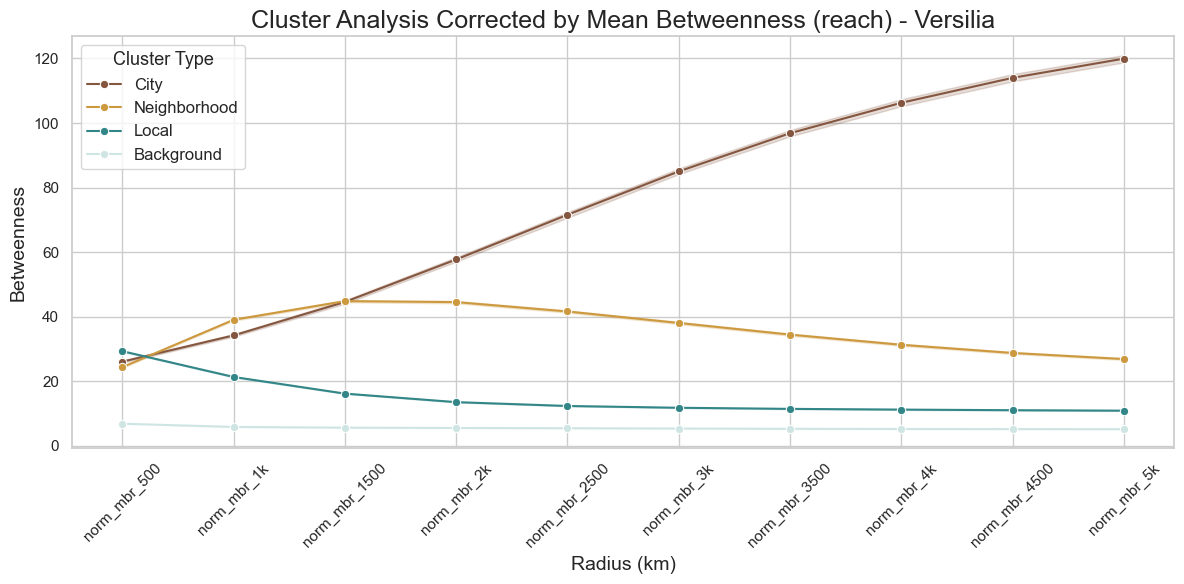

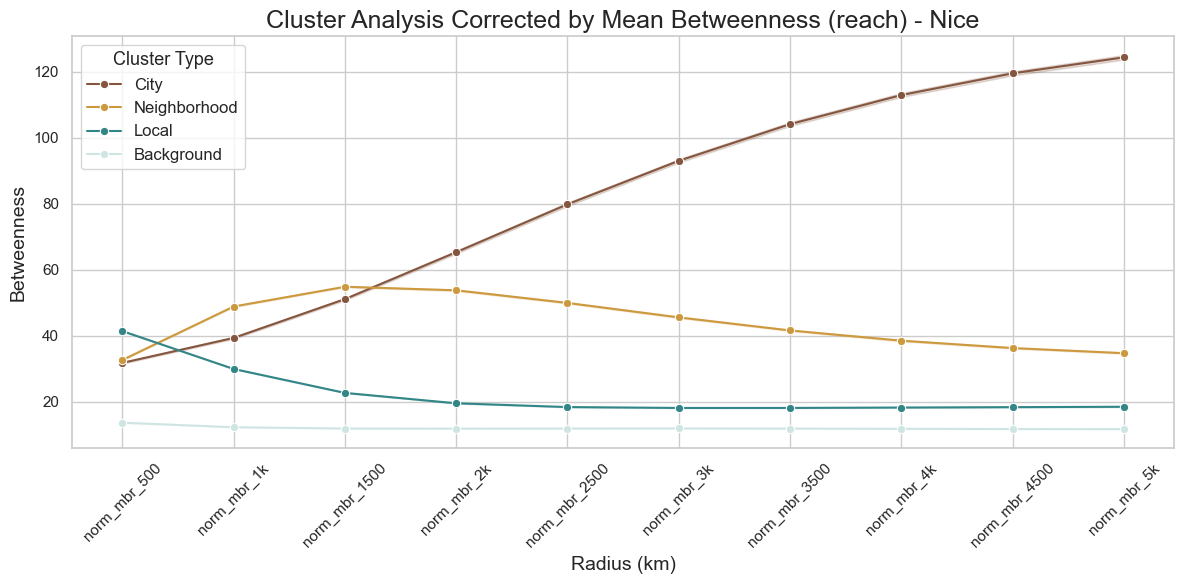

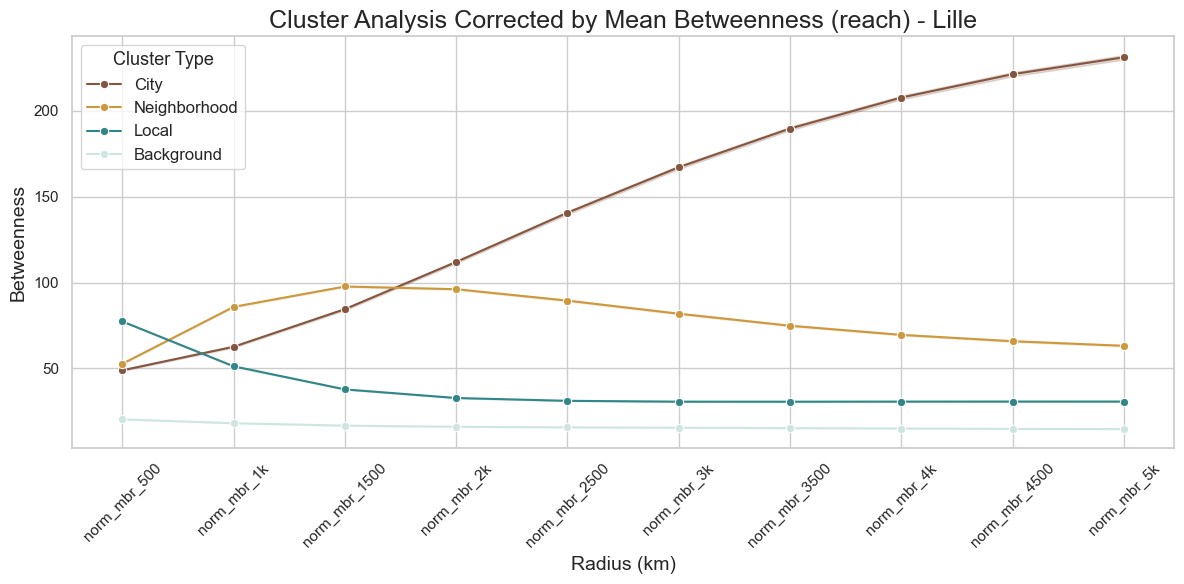

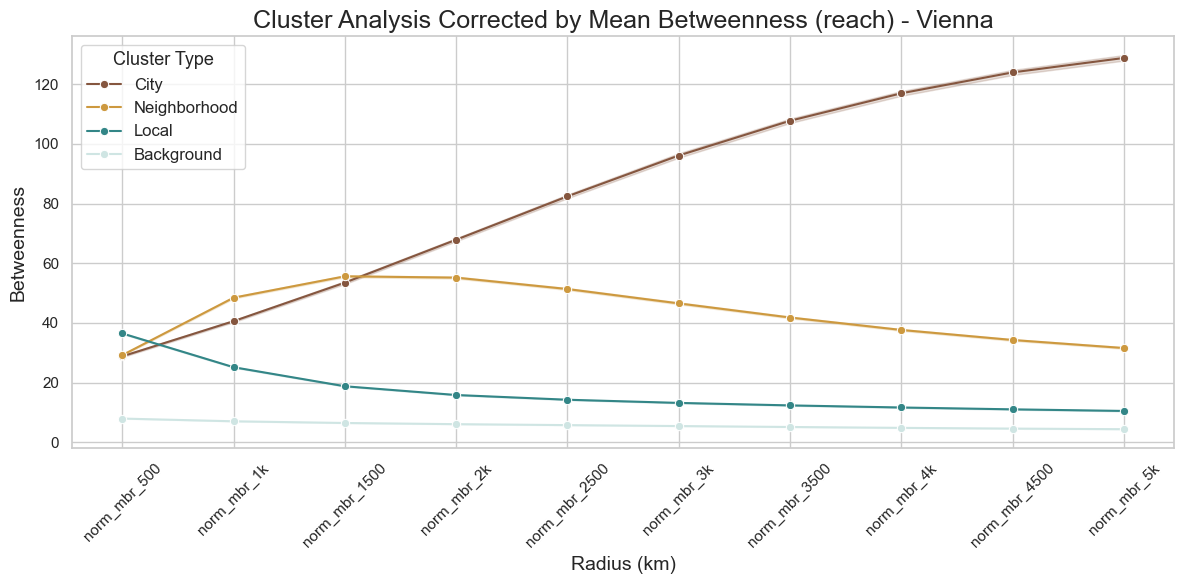

In [29]:
# Define corrected colors for each cluster type
cluster_palette = {
    'City': '#85563F',         # marrom
    'Neighborhood': '#cd993f', # mostarda
    'Local': '#338687',        # teal
    'Background': '#cfe5e3'    # azul claro
}

# Map numeric cluster labels (0–3) to corrected descriptive names
cluster_label_map = {
    0: 'Local',
    1: 'Neighborhood',
    2: 'Background',
    3: 'City'
}

# Order for plotting and legend (matches desired label-color association)
cluster_order = ['City', 'Neighborhood', 'Local', 'Background']

# Filter the columns that start with 'zscore_abw'
zscore_columns = [col for col in combined_pca_clustering_results.columns if col.startswith('zscore_abw')]

# Map numeric cluster values to descriptive labels
combined_pca_clustering_results['cluster_4_label'] = combined_pca_clustering_results['cluster_4'].map(cluster_label_map)

# Loop through each city
for city in combined_pca_clustering_results['city'].unique():
    city_data = combined_pca_clustering_results[combined_pca_clustering_results['city'] == city]

    # Melt the data for plotting (normalized values)
    melted_no_scaling = city_data.melt(
        id_vars=['cluster_4_label'],
        value_vars=norm_columns,  # assuming this is already defined
        var_name='norm variable',
        value_name='value'
    )

    # Plot settings
    sns.set(style='whitegrid')
    plt.figure(figsize=(12, 6))

    # Plot with custom palette and cluster label as hue
    ax = sns.lineplot(
        data=melted_no_scaling,
        x='norm variable',
        y='value',
        hue='cluster_4_label',
        hue_order=cluster_order,
        palette=cluster_palette,
        marker='o'
    )

    # Title and axis labels
    plt.title(f'Cluster Analysis Corrected by Mean Betweenness (reach) - {city}', fontsize=18)
    plt.xlabel('Radius (km)', fontsize=14)
    plt.ylabel('Betweenness', fontsize=14)
    plt.xticks(rotation=45)

    # Fix legend to match cluster_order and palette
    handles, labels = ax.get_legend_handles_labels()
    label_to_handle = dict(zip(labels, handles))
    ordered_handles = [label_to_handle[label] for label in cluster_order if label in label_to_handle]
    plt.legend(
        handles=ordered_handles,
        labels=cluster_order,
        title='Cluster Type',
        fontsize=12,
        title_fontsize=13,
        loc='upper left'
    )

    # Layout and export
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(
        f'C:/Users/monaliza/PycharmProjects/paper-multiscalar-foreground-network/0_data-visualization/4-mbr-cluster-lineplot-{city}.png',
        format='png', dpi=300, bbox_inches='tight'
    )
    plt.show()

In [26]:
export(combined_pca_clustering_results, '4_mbr_zscores_results_nms_combined_cities', 's8_paper_multiscalar_foreground_network', engine)